In [6]:
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.cm as cm

from scipy.integrate import trapezoid
from scipy.interpolate import make_smoothing_spline
from scipy.special import  j0, j1
from lifesimmc.lib.colormaps import cmap_blue

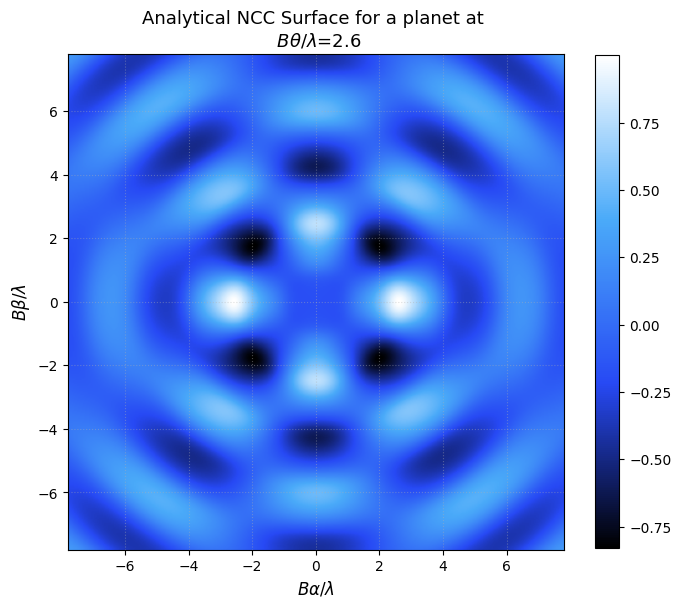

In [7]:
def compute_analytical_ncc(inv1,  phi1, inv2_grid, PHI2_grid):
    """
    Computes exact NCC surface against a fixed reference template (r1, phi1).
    inv  = B * theta / lambda
    """

    # Angle difference between candidate phi2 and reference phi1
    delta_phi = PHI2_grid - phi1
    cos_dphi = np.cos(delta_phi)

    
    
    # Effective distances R_minus and R_plus
    R_minus = np.sqrt(inv1**2 + inv2_grid**2 - 2 * inv1 * inv2_grid * cos_dphi)
    R_plus  = np.sqrt(inv1**2 + inv2_grid**2 + 2 * inv1 * inv2_grid * cos_dphi)
    
    # Numerator & Denominator
    numerator = j0(2* R_minus) + j0(2* R_plus)
    
    E1 = 1.0 + j0(4 * inv1)
    E2 = 1.0 + j0(4 * inv2_grid)
    denominator = np.sqrt(E1 * E2)
    
    return numerator / denominator

# --- Parameters Setup ---

# Reference template position in polar coordinates
phi1 = 0*np.pi  # 45 degrees
inv1 = 2.6 # B theta / lambda


# Parameter space grid in Cartesian space (x, y)
max_inv = 3*inv1
grid_points = 400
x_vals = np.linspace(-max_inv, max_inv, grid_points)
y_vals = np.linspace(-max_inv, max_inv, grid_points)
X, Y = np.meshgrid(x_vals, y_vals)

# Parametrize r2 and phi2 from X and Y
INV2 = np.sqrt(X**2 + Y**2)
PHI2 = np.arctan2(Y, X)

# --- Compute Exact NCC Surface ---
ncc_surface = compute_analytical_ncc(inv1, phi1, INV2, PHI2)

# --- Plotting 2D Spatial Circular Image ---
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(ncc_surface, 
    extent=[-max_inv, max_inv, -max_inv, max_inv], 
    origin='lower',  cmap=cmap_blue)
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title(f'Analytical NCC Surface for a planet at \n' + fr' $B  \theta / \lambda $={round(inv1 ,2)}', fontsize=13)
ax.set_xlabel(r'$B \alpha / \lambda$', fontsize=12)
ax.set_ylabel(r'$B \beta / \lambda$', fontsize=12)
ax.set_aspect('equal')
ax.grid(True, linestyle=':', alpha=0.4)
plt.savefig("plots/ncc_examples.png", dpi = 300, transparent = True)
plt.show()
plt.close()







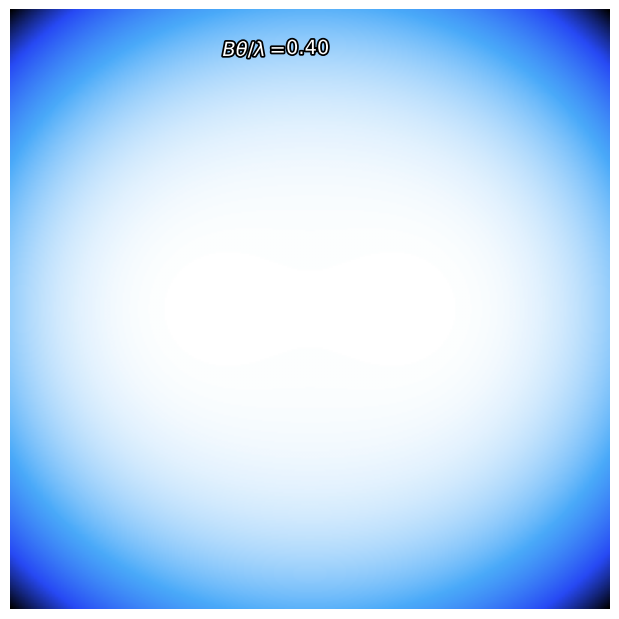

In [8]:
# Source - https://stackoverflow.com/a/13983801
# Posted by tacaswell, modified by community. See post 'Timeline' for change history
# Retrieved 2026-08-12, License - CC BY-SA 3.0

import matplotlib.patheffects as pe
import numpy as np
from PIL import Image
from pylab import *


dpi = 150

# No margins and no axis chrome so the image fills the entire frame --
# opaque throughout, so no transparent-background GIF ghosting.
fig, ax = plt.subplots(figsize=(6, 6))
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
ax.set_axis_off()

grid_points = 400


n_frames = 91

def gen_NCC(n):
    # Parameter space grid in Cartesian space (x, y)
    inv1 = (n_frames - n)*0.03 + 0.01
    max_inv = 3*inv1
    x_vals = np.linspace(-max_inv, max_inv, grid_points)
    y_vals = np.linspace(-max_inv, max_inv, grid_points)
    X, Y = np.meshgrid(x_vals, y_vals)

    # Parametrize r2 and phi2 from X and Y
    INV2 = np.sqrt(X**2 + Y**2)
    PHI2 = np.arctan2(Y, X)

    # --- Compute Exact NCC Surface ---
    ncc_surface = compute_analytical_ncc(inv1, phi1, INV2, PHI2)

    return ncc_surface


im = ax.imshow(gen_NCC(0), cmap=cmap_blue)

# Title split into a static label (fixed anchor, right-aligned) and a
# dynamic value (same anchor, left-aligned) so the "B theta/lambda" label
# never shifts position as the number's width changes between frames.
# Drawn on top of the image itself (axes-fraction coords) with a black
# stroke outline so it stays legible over the colormap regardless of the
# underlying color.
text_kwargs = dict(color="white", fontsize=14,
                    path_effects=[pe.withStroke(linewidth=2.5, foreground="black")])
label = ax.text(0.46, 0.95, r"$B \theta / \lambda = $", transform=ax.transAxes, ha="right", va="top", **text_kwargs)
value = ax.text(0.46, 0.95, "", transform=ax.transAxes, ha="left", va="top", **text_kwargs)


# Render every frame and quantize it to a GIF palette by hand instead of
# letting matplotlib's animation.FuncAnimation + PillowWriter do it
# automatically. The viridis gradient alone is smooth and highly varied,
# so it eats up nearly all 256 palette slots -- the automatic quantizer
# then has no room left for true white, and the white title text gets
# silently remapped to the nearest available color, which turns out to
# be a pale yellow-green. Reserving 2 explicit slots (pure white + pure
# black) up front, shared across every frame, guarantees the text stays
# crisp regardless of what colors the background happens to use.

base_palette_img = None
frames = []
for n in range(n_frames):
    ncc = gen_NCC(n)
    im.set_array(ncc)
    im.set_clim(vmin=ncc.min(), vmax=ncc.max())
    # ":.2f" fixes the decimal count at 2 digits (e.g. "0.50" not "0.5"),
    # unlike np.round() which returns a float and drops trailing zeros
    # when stringified.
    value.set_text(f"{(n_frames-n)*0.04 + 0.36:.2f}")

    fig.canvas.draw()
    rgba = np.asarray(fig.canvas.buffer_rgba())
    rgb_img = Image.fromarray(rgba[:, :, :3], mode="RGB")

    if base_palette_img is None:
        quantized = rgb_img.quantize(colors=254, method=Image.Palette.ADAPTIVE, dither=Image.Dither.NONE)
        pal = quantized.getpalette()
        pal[254 * 3:254 * 3 + 3] = [255, 255, 255]
        pal[255 * 3:255 * 3 + 3] = [0, 0, 0]
        quantized.putpalette(pal)
        base_palette_img = quantized
    else:
        quantized = rgb_img.quantize(palette=base_palette_img, dither=Image.Dither.NONE)
    frames.append(quantized)

# duration=100ms/frame matches the old fps=10 PillowWriter setting
frames[0].save('plots/imshow_animation.gif', save_all=True, append_images=frames[1:],
               duration=100, loop=0, optimize=False)


frames[0].save('plots/imshow_animation_0.png')


frames[-1].save(f'plots/imshow_animation_{n_frames}.png')

plt.show()


In [9]:
# ---------------------------------------------------------------
# Numerical NCC (used only to verify the analytic formulas)
# ---------------------------------------------------------------
def x_signal(inv, phi, t):
    A = np.pi * i
    return np.sin(np.pi * inv * np.sin(t + phi)) ** 2


def ncc_numeric(inv0, phi0, inv, phi, t):
    x0 = x_signal(inv0, phi0, t)
    x1 = x_signal(inv, phi, t)
    u0 = x0 - x0.mean()
    u1 = x1 - x1.mean()
    return (u0 @ u1) / (np.linalg.norm(u0) * np.linalg.norm(u1))


def numeric_curvatures(inv0, phi0, N=4000, h_r=1e-4, h_phi=1e-3, case = None):
    t = np.linspace(0, 2 * np.pi, N, endpoint=False)
    f = lambda inv, phi: ncc_numeric(inv0, phi0, inv, phi, t)
    f0 = f(inv0, phi0) # must be equal to 1
    H_rr = (f(inv0 + h_r, phi0) - 2 * f0 + f(inv0 - h_r, phi0)) / h_r ** 2 
    if(case == 'angular'):
        H_phiphi = (f(inv0, phi0 + h_phi) - 2 * f0 + f(inv0, phi0 - h_phi)) / h_phi ** 2 # return in curvature of phi [rad]
    else:
        dr = inv0 *(1 - np.cos(h_phi))
        H_phiphi = (f(inv0 + dr, phi0 + h_phi) - 2 * f0 + f(inv0 + dr, phi0 - h_phi)) / (inv0 * h_phi) ** 2 # returns in curvature of r * phi
    H_rphi = (
        f(inv0 + h_r, phi0 + h_phi)
        - f(inv0 + h_r, phi0 - h_phi)
        - f(inv0 - h_r, phi0 + h_phi)
        + f(inv0 - h_r, phi0 - h_phi)
    ) / (4 * h_r * h_phi)
    return H_rr, H_phiphi, H_rphi



def kappa_pearson(inv): # compute the derivative of NCC with respect to the invariant coordinates (B*alpha / lambda) and (B*beta / lambda)
    """Radial and tangential curvature (kappa_r, kappa_t) of the Pearson
    correlation peak at radius r1, wavenumber k."""
    #r = r1_as * np.pi / 180 / 3600  # [rad]
    #r1, B = np.meshgrid(r, Baselines, indexing="ij")  # (nr, nB)
    #k =  B / lam
    #inv = k* r1
    inv_pi = np.pi * inv
    x0 = 2 * inv_pi
    y0 = 4 * inv_pi
    P0, P1 = j0(x0), j1(x0)
    Q0, Q1 = j0(y0), j1(y0)
    V1 = (1 + Q0) / 2 - P0**2   # Var(f) at this r1
 
    kappa_t =  (Q1 / (2 * inv * np.pi) - 1) / V1
    kappa_t *= np.pi**2
 
    num_r = (8*P0**2*Q0 - 2*P0**2*Q1/inv_pi - 4*P0**2
             + 16*P0*P1*Q1 - 8*P1**2*Q0- 8*P1**2
             - 4*Q0**2 + Q0*Q1/inv_pi - 2*Q0 - 4*Q1**2
             + Q1/inv_pi + 2)
    den_r =  (2*P0**2 - Q0 - 1) * (2 * V1)
    kappa_r = num_r / den_r
    kappa_r *= np.pi**2
    return  kappa_r ,  kappa_t  # [inv^-2]

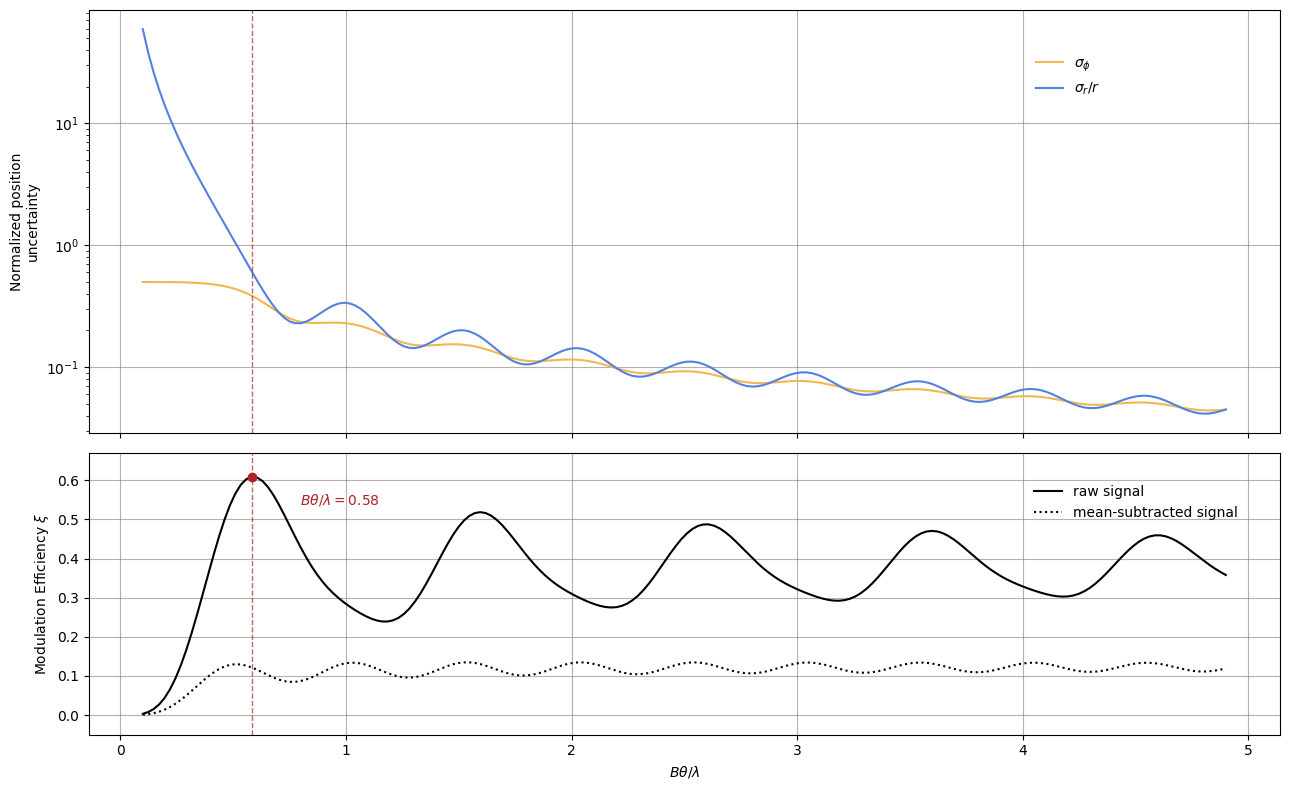

In [78]:
inv = np.linspace(0.1, 4.9, 200)
H_rr_a, H_phi_a = kappa_pearson(inv)

t = np.linspace(0, 2*np.pi, 1000)
xs = np.zeros((len(inv), len(t)))
for i in range(len(inv)):
    xs[i, :] = x_signal(inv[i], 0, t)
throughput = np.mean(xs**2, axis=1)
throughput2 = np.mean((xs-np.mean(xs, axis = 1)[:,None])**2, axis=1)

inv_at_max_throughput = inv[np.argmax(throughput)]

fig, (ax, ax2) = plt.subplots(
    2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [3, 2]}
)

ax.plot(inv, 1 / np.sqrt(-H_phi_a) / inv, label=r"$\sigma_\phi$", color = "#F2B750")
ax.plot(inv, 1 / np.sqrt(-H_rr_a) / inv, label=r"$\sigma_r / r$", color = "#5481DF")

ax.set_yscale("log")
#ax.set_xscale('log')
ax.set_ylabel("Normalized position\nuncertainty")
ax.legend(loc="upper right", bbox_to_anchor=(0.86, 0.92), framealpha=0., fontsize = 10)
ax.grid(True, alpha=0.6, color = '#867F6C')

ax2.plot(inv, throughput, color="k", label = "raw signal")
ax2.plot(inv, throughput2, "k:", label = "mean-subtracted signal")
#ax2.plot(inv, throughput2/throughput, color="blue")
ax2.plot(inv_at_max_throughput, throughput.max(), "o", color="#AF2228", zorder=5)
ax2.set_ylabel(r"Modulation Efficiency $\xi$")
ax2.set_xlabel(r"$B \theta / \lambda$")
ax2.grid(True, alpha=0.6, color = '#867F6C')
ax2.set_ylim(bottom = -0.05, top = 0.67)
ax2.legend(loc="upper right", bbox_to_anchor=(0.975, 0.93), framealpha=0., fontsize = 10)

for a in (ax, ax2):
    a.axvline(inv_at_max_throughput, color="#AF2228", linestyle="--", linewidth=1, alpha=0.7)

ax2.annotate(
    fr"$B\theta/\lambda = {inv_at_max_throughput:.2f}$",
    xy=(inv_at_max_throughput, throughput.max()),
    xytext=(35, -20),
    textcoords="offset points",
    color="#AF2228",
    fontsize=10,
)
plt.tight_layout()
plt.savefig("plots/sigma_inv.png", dpi = 300, transparent = True)
plt.show()
plt.close()